# Week 05 — YCB-V Error Analysis I
**Group 1 | Main Quest: Structuring Machine Learning Projects**  
**Side Quest: Error Analysis I**

This notebook is based on your actual `week04_object_classification_improvement(2).ipynb`, **not** an alternate dataset, notebook, or newly trained model. It uses the same BOP'19 YCB-V subset, five selected objects, scene-level split, 64 × 64 RGB GT-box crops (+8% padding), and selected E1 model (Adam, dropout=0.30, weight_decay=1e-4). In the original run: 877 train / 375 validation / 450 test samples, across 8/2/2 scenes.

**Run Part A → Part B → Part C immediately.** Both B and C have real, complete Week 04 results even without a saved CSV or checkpoint, because the *full 5 × 5 confusion matrix* is legible in the original executed Week 04 notebook and is reproduced exactly below. The example-image figures are also taken from that executed notebook. These are **Week 04 observations**, not new Week 05 model runs.

**Optional Part D** reads original `outputs/week04/final_test_predictions.csv` for *per-image*, *per-scene*, *confidence*, and *crop* diagnostics. If the CSV is missing but the original YCB-V dataset **and** original `E1_regularization.pt` are still accessible, Part D can reconstruct exactly the Week 04 scene split and perform inference without retraining. If neither exists, no missing predictions are fabricated.

**Important:** Week 03/04 internally split scenes from the official BOP'19 **test subset**. Their held-out test scenes are an internal test, **not** the official YCB-V train/test benchmark.

## Part A — Original Week 04 experiment settings and exact observed matrix

The matrix below is transcribed cell-for-cell from the confusion-matrix **figure embedded in the uploaded executed Week 04 notebook** (`cell 30`, first figure). Rows are true classes; columns are predictions. This fixes the earlier notebook's incorrect assumption that only the report's *partial* matrix was available.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CLASSES = [
    "tomato_soup_can", "sugar_box", "master_chef_can",
    "tuna_fish_can", "bleach_cleanser",
]
SELECTED_OBJ_IDS = [4, 3, 1, 6, 12]  # original Week04 class order

# Verified directly from uploaded Week04 notebook's original confusion-matrix figure.
W4_E1_CM = np.array([
    [74,  0,  0, 31, 45],  # true tomato_soup_can
    [ 0, 29,  0,  0, 46],  # true sugar_box
    [ 7,  0, 68,  0,  0],  # true master_chef_can
    [69,  0,  0,  6,  0],  # true tuna_fish_can
    [32, 12,  0, 20, 11],  # true bleach_cleanser
], dtype=int)

W4_TRAIN_ACC = 1.0000       # training accuracy at selected E1 checkpoint (reported)
W4_VAL_ACC = 0.9893         # reported to four decimal places
W4_TEST_ACC = 188 / 450    # recomputed exactly from confusion-matrix counts
W3_TEST_ACC = 0.5133       # Week 03 report comparison (rounded)

assert W4_E1_CM.shape == (5, 5)
assert W4_E1_CM.sum(axis=1).tolist() == [150, 75, 75, 75, 75]
assert W4_E1_CM.sum() == 450 and np.trace(W4_E1_CM) == 188
assert round(W4_TEST_ACC, 4) == 0.4178
print('Same original BOP subset | E1_regularization | 450 test examples')
print(f'Week04 test accuracy: {W4_TEST_ACC:.4%} (188/450)')
print('Classes in original label order:', CLASSES)


Same original BOP subset | E1_regularization | 450 test examples
Week04 test accuracy: 41.7778% (188/450)
Classes in original label order: ['tomato_soup_can', 'sugar_box', 'master_chef_can', 'tuna_fish_can', 'bleach_cleanser']


## Part B — **Complete** confusion analysis (works without any external files)

This is the exact complete matrix printed by the executed Week 04 E1 run, **not** an inferred or partially filled matrix. Normalized values tell you the share of each true class predicted as each class. No checkpoint loading or CSV is needed.

Full confusion matrix — true labels in rows; predicted labels in columns:


,tomato_soup_can,sugar_box,master_chef_can,tuna_fish_can,bleach_cleanser
tomato_soup_can,74,0,0,31,45
sugar_box,0,29,0,0,46
master_chef_can,7,0,68,0,0
tuna_fish_can,69,0,0,6,0
bleach_cleanser,32,12,0,20,11


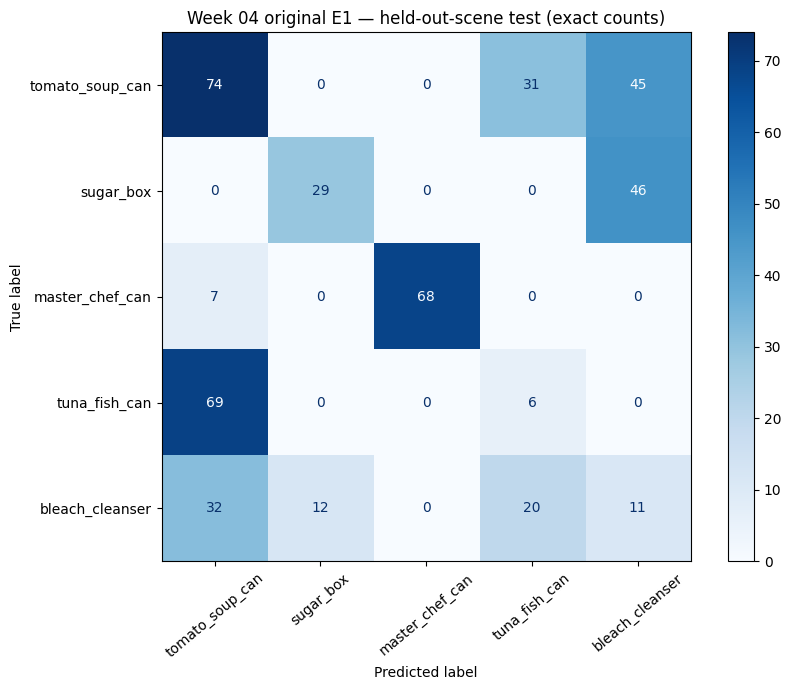

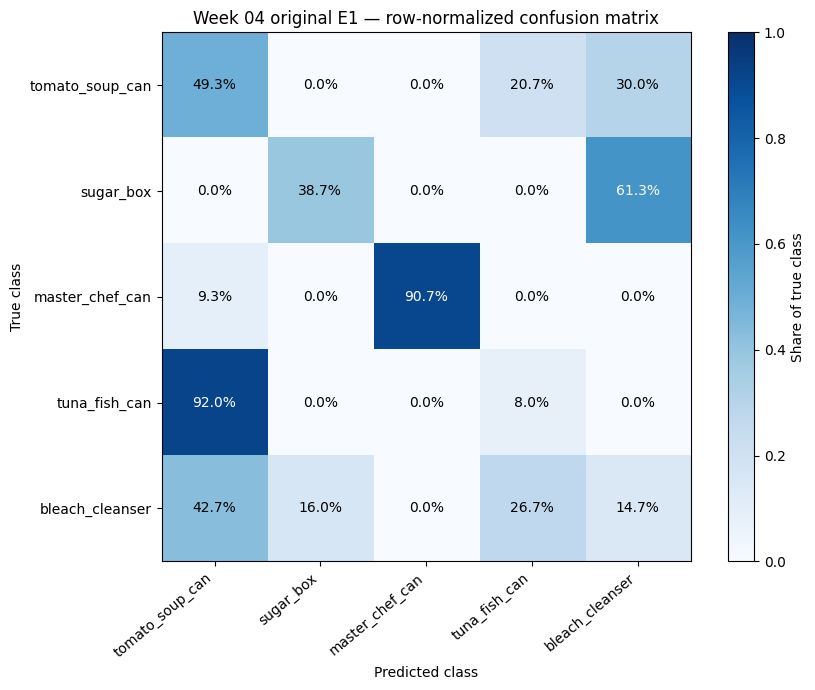

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_df = pd.DataFrame(W4_E1_CM, index=CLASSES, columns=CLASSES)
print('Full confusion matrix — true labels in rows; predicted labels in columns:')
display(cm_df)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(W4_E1_CM, display_labels=CLASSES).plot(
    ax=ax, cmap='Blues', values_format='d', xticks_rotation=40, colorbar=True
)
ax.set_title('Week 04 original E1 — held-out-scene test (exact counts)')
plt.tight_layout()
plt.show()

row_normalized = W4_E1_CM / W4_E1_CM.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(row_normalized, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(5), CLASSES, rotation=40, ha='right')
ax.set_yticks(range(5), CLASSES)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{row_normalized[i, j]:.1%}', ha='center', va='center',
                color='white' if row_normalized[i, j] > 0.5 else 'black')
ax.set(xlabel='Predicted class', ylabel='True class',
       title='Week 04 original E1 — row-normalized confusion matrix')
fig.colorbar(im, ax=ax, label='Share of true class')
plt.tight_layout()
plt.show()


### Original Week 04 source figure (embedded in your uploaded notebook)

The figure below is retained as visual provenance. The newly generated matrix above should match it exactly.

![Original Week04 E1 confusion matrix](attachment:original_week04_confusion.jpg)

## Part C — Quantify and inspect the original E1 errors

Compute precision, recall, F1, per-class error counts, class-confusion transitions, and training/validation/test gaps from the *same* original Week 04 E1 data. These operations are genuine new Week 05 analysis of the existing Week 04 results; they do **not** claim any additional Week 05 training/evaluation.

,class,support,correct,errors,precision,recall,f1,error_rate,share_of_all_errors
0,tomato_soup_can,150,74,76,0.4066,0.4933,0.4458,0.5067,0.2901
1,sugar_box,75,29,46,0.7073,0.3867,0.5000,0.6133,0.1756
2,master_chef_can,75,68,7,1.0000,0.9067,0.9510,0.0933,0.0267
3,tuna_fish_can,75,6,69,0.1053,0.0800,0.0909,0.9200,0.2634
4,bleach_cleanser,75,11,64,0.1078,0.1467,0.1243,0.8533,0.2443


Macro F1:     0.4224
Weighted F1:  0.4263
Test accuracy: 41.7778%


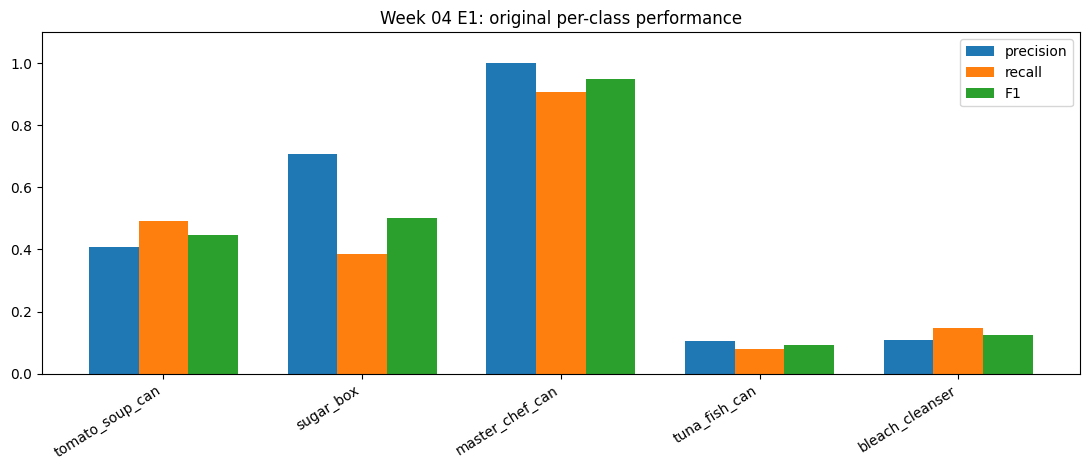

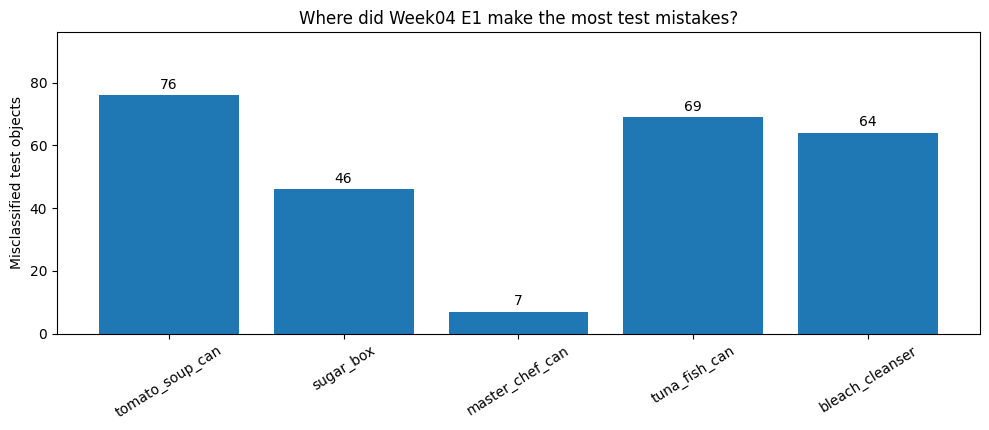

In [3]:
support = W4_E1_CM.sum(axis=1)
predicted_n = W4_E1_CM.sum(axis=0)
tp = np.diag(W4_E1_CM)
precision = np.divide(tp, predicted_n, out=np.zeros(5, dtype=float), where=predicted_n>0)
recall = tp / support
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros(5, dtype=float), where=(precision + recall)>0)

per_class = pd.DataFrame({
    'class': CLASSES,
    'support': support,
    'correct': tp,
    'errors': support - tp,
    'precision': precision,
    'recall': recall,
    'f1': f1,
    'error_rate': 1 - recall,
    'share_of_all_errors': (support - tp) / (W4_E1_CM.sum() - np.trace(W4_E1_CM)),
})
display(per_class.round(4))
print('Macro F1:    ', f'{f1.mean():.4f}')
print('Weighted F1: ', f'{np.average(f1, weights=support):.4f}')
print('Test accuracy:', f'{np.trace(W4_E1_CM) / W4_E1_CM.sum():.4%}')

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(5)
width = 0.25
ax.bar(x - width, precision, width, label='precision')
ax.bar(x, recall, width, label='recall')
ax.bar(x + width, f1, width, label='F1')
ax.set_xticks(x, CLASSES, rotation=32, ha='right')
ax.set_ylim(0, 1.10)
ax.set_title('Week 04 E1: original per-class performance')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(CLASSES, per_class['errors'])
for i, n in enumerate(per_class['errors']):
    ax.text(i, int(n) + 2, str(int(n)), ha='center')
ax.set_ylim(0, max(per_class['errors']) + 20)
ax.set_ylabel('Misclassified test objects')
ax.set_title('Where did Week04 E1 make the most test mistakes?')
ax.tick_params(axis='x', rotation=32)
plt.tight_layout()
plt.show()


### Part C1 — All observed confusion transitions and the accuracy gap

These transitions use **every** non-diagonal cell in the original image, not merely the five transitions mentioned in the Week 04 written report. A mismatch between two small scene groups and the test scenes is a **hypothesis** requiring image/scene investigation, not an established causal explanation.

All wrong true-class → predicted-class transitions:


,true_class,predicted_class,count,share_of_true_class,share_of_all_262_errors
0,tuna_fish_can,tomato_soup_can,69,0.9200,0.2634
1,sugar_box,bleach_cleanser,46,0.6133,0.1756
2,tomato_soup_can,bleach_cleanser,45,0.3000,0.1718
3,bleach_cleanser,tomato_soup_can,32,0.4267,0.1221
4,tomato_soup_can,tuna_fish_can,31,0.2067,0.1183
5,bleach_cleanser,tuna_fish_can,20,0.2667,0.0763
6,bleach_cleanser,sugar_box,12,0.1600,0.0458
7,master_chef_can,tomato_soup_can,7,0.0933,0.0267


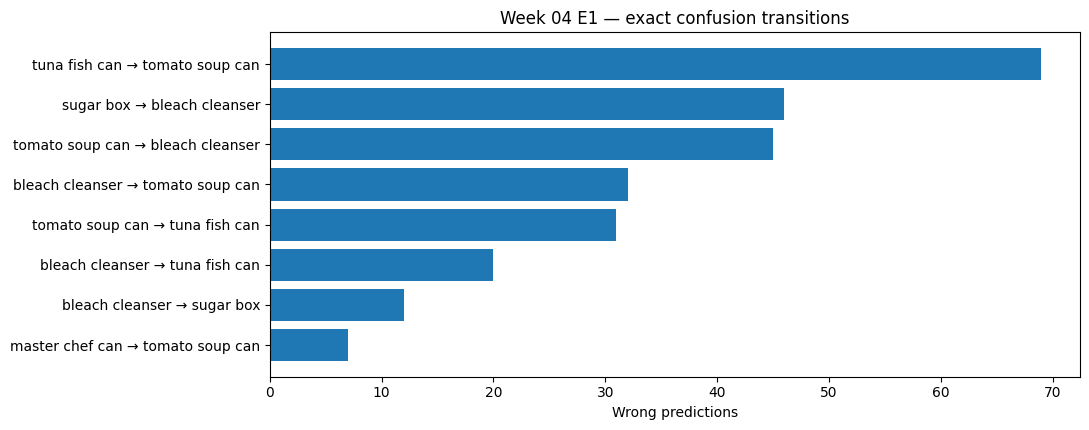

,split,accuracy
0,Train (selected epoch),1.000000
1,Validation (selected epoch),0.989300
2,Test (held-out scenes),0.417778


Train − validation gap: 1.07%
Validation − test gap: 57.15%
Week04 − Week03 test change: -9.55% (Week03 percentage rounded)


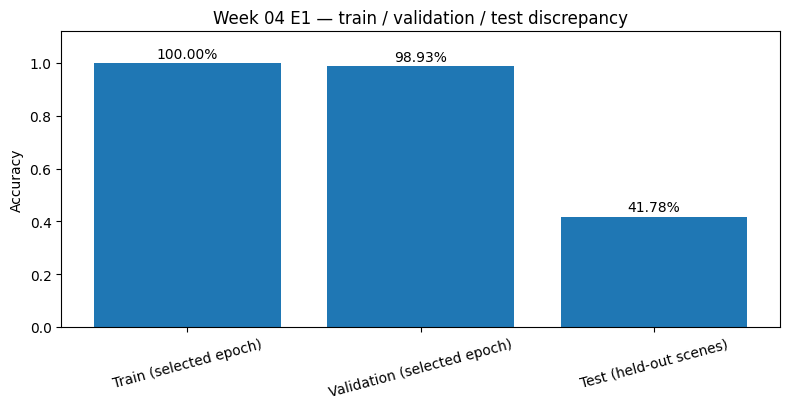

In [4]:
transitions = []
for i, true_name in enumerate(CLASSES):
    for j, predicted_name in enumerate(CLASSES):
        if i != j and W4_E1_CM[i, j] > 0:
            transitions.append({
                'true_class': true_name,
                'predicted_class': predicted_name,
                'count': int(W4_E1_CM[i, j]),
                'share_of_true_class': W4_E1_CM[i, j] / support[i],
                'share_of_all_262_errors': W4_E1_CM[i, j] / (450 - 188),
            })
transitions = pd.DataFrame(transitions).sort_values('count', ascending=False).reset_index(drop=True)
print('All wrong true-class → predicted-class transitions:')
display(transitions.round(4))

fig, ax = plt.subplots(figsize=(11, 4.4))
labels = transitions['true_class'].str.replace('_', ' ') + ' → ' + transitions['predicted_class'].str.replace('_', ' ')
ax.barh(labels, transitions['count'])
ax.invert_yaxis()
ax.set(xlabel='Wrong predictions', title='Week 04 E1 — exact confusion transitions')
plt.tight_layout()
plt.show()

split_accuracy = pd.DataFrame({
    'split': ['Train (selected epoch)', 'Validation (selected epoch)', 'Test (held-out scenes)'],
    'accuracy': [W4_TRAIN_ACC, W4_VAL_ACC, W4_TEST_ACC],
})
display(split_accuracy)
print(f'Train − validation gap: {W4_TRAIN_ACC - W4_VAL_ACC:.2%}')
print(f'Validation − test gap: {W4_VAL_ACC - W4_TEST_ACC:.2%}')
print(f'Week04 − Week03 test change: {W4_TEST_ACC - W3_TEST_ACC:+.2%} (Week03 percentage rounded)')
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(split_accuracy['split'], split_accuracy['accuracy'])
for i, value in enumerate(split_accuracy['accuracy']):
    ax.text(i, value + .02, f'{value:.2%}', ha='center')
ax.set_ylim(0, 1.12)
ax.set_ylabel('Accuracy')
ax.set_title('Week 04 E1 — train / validation / test discrepancy')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()


### Part C2 — Original Week 04 examples (embedded; available offline)

These are original displayed crops, predictions, and confidence labels from the uploaded *executed* Week 04 notebook. They are examples (some may be near-duplicate frames); **do not treat this small displayed sample as a representative error-frequency estimate**.

**Original correct predictions** — exact Week 04 figure.

![week04_correct.jpg](attachment:week04_correct.jpg)

**Original wrong predictions** — exact Week 04 figure. Notice several confidence values close to 1.00. Crop contamination is visible in some examples, but cause is not established.

![week04_wrong.jpg](attachment:week04_wrong.jpg)

## Part D (optional) — Connect the **original per-sample Week 04 E1 predictions**

The original uploaded Week 04 code **already saves** `outputs/week04/final_test_predictions.csv` in **cell 28**, alongside `outputs/week04/checkpoints/E1_regularization.pt`, `outputs/week04/split_summary.csv`, and `outputs/week04/week04_metrics.json`.

You do **not** need to train a new model. This section first checks the **existing in-memory** `pred_df` if you paste the cells into the *same executed Week 04 runtime*, then tries the original CSV name in known directories. It strictly validates the 450 records and checks their full confusion matrix against the original embedded figure. If the file is not accessible, Part B and C above **remain complete**; optional scene/image/confidence diagnostics are accurately marked unavailable.

To use Google Drive in Colab, mount Drive yourself and point `PREDICTIONS_CSV` to the exact file from the **original E1** run, not a modified or retrained model.

In [5]:
from pathlib import Path

# Optional exact path if Colab runs in a different folder or you copied the Week04 CSV:
PREDICTIONS_CSV = None  # e.g. '/content/drive/MyDrive/AnnaCV/outputs/week04/final_test_predictions.csv'

# The file name and columns below are taken directly from your ORIGINAL Week04 cell 28.
SEARCH_DIRS = [
    Path('outputs/week04'),
    Path('/content/outputs/week04'),
    Path('/content/drive/MyDrive/YCBV_Internship/week04_final/outputs/week04'),
    Path('/content/drive/MyDrive/YCBV_Internship/week04_final'),
    Path('/content/drive/MyDrive/AnnaCV/outputs/week04'),
    Path('/content/drive/MyDrive'),
]

def verify_original_e1_predictions(raw):
    df = raw.copy().reset_index(drop=True)
    needed = {'class_name', 'pred_class', 'confidence', 'scene_id', 'im_id', 'rgb_path',
              'obj_id', 'x', 'y', 'w', 'h'}
    missing = sorted(needed - set(df.columns))
    if missing:
        raise ValueError(f'This is not the original Week04 final_test_predictions CSV; missing columns: {missing}')
    if len(df) != 450:
        raise ValueError(f'Wrong run: got {len(df)} predictions, expected 450')
    if not df['class_name'].isin(CLASSES).all() or not df['pred_class'].isin(CLASSES).all():
        raise ValueError('Unexpected class names; do not mix checkpoints or dataset variants')
    observed = pd.crosstab(df['class_name'], df['pred_class']).reindex(
        index=CLASSES, columns=CLASSES, fill_value=0).to_numpy()
    if not np.array_equal(observed, W4_E1_CM):
        raise ValueError(f'Found a different run/checkpoint (matrix does not match original E1).\n{observed}')
    df['correct'] = df['class_name'] == df['pred_class']
    df['confidence'] = pd.to_numeric(df['confidence'], errors='coerce')
    return df

# NOTE: in a separate notebook, the original Week04 pred_df variable is not automatically shared.
# This check only works if these cells are pasted/run in the same live runtime.
original_predictions = None
if 'pred_df' in globals() and isinstance(globals()['pred_df'], pd.DataFrame):
    try:
        original_predictions = verify_original_e1_predictions(globals()['pred_df'])
        print('Connected to verified ORIGINAL Week04 live pred_df')
    except ValueError as e:
        print('Live pred_df not the matching Week04 E1 run:', str(e)[:300])

candidates = []
if PREDICTIONS_CSV:
    candidates = [Path(PREDICTIONS_CSV)]
else:
    for root in SEARCH_DIRS:
        if root.is_file() and root.name == 'final_test_predictions.csv':
            candidates.append(root)
        elif root.is_dir():
            # Avoid searching all of MyDrive recursively; check known top-level destinations.
            candidates.extend([root / 'final_test_predictions.csv', root / 'week04' / 'final_test_predictions.csv',
                               root / 'outputs' / 'week04' / 'final_test_predictions.csv'])

seen = set()
for p in candidates:
    if original_predictions is not None: break
    if str(p) in seen: continue
    seen.add(str(p))
    if p.is_file():
        try:
            original_predictions = verify_original_e1_predictions(pd.read_csv(p))
            print('Loaded and verified original E1 predictions:', p.resolve())
        except (ValueError, OSError) as e:
            print('Skipped nonmatching/unreadable file', str(p), ':', str(e)[:200])

if original_predictions is None:
    print('Original per-image CSV not found. B/C ABOVE are fully populated with real Week04 results.')
    print('Optional scene-wise, per-image and confidence analyses will wait for the saved E1 CSV,')
    print('or use the original dataset + checkpoint in Part E (no retraining).')


Original per-image CSV not found. B/C ABOVE are fully populated with real Week04 results.
Optional scene-wise, per-image and confidence analyses will wait for the saved E1 CSV,
or use the original dataset + checkpoint in Part E (no retraining).


### Part D1 — Per-scene test breakdown & confidence diagnostics (runs **only** with verified E1 CSV)

Unlike the complete matrix above, these per-image statistics **cannot** be recovered from a report or confusion-matrix figure alone.

In [6]:
if original_predictions is not None:
    scene_summary = original_predictions.groupby('scene_id').agg(
        total=('correct', 'size'), correct=('correct', 'sum'),
        accuracy=('correct', 'mean'), mean_confidence=('confidence', 'mean')
    ).sort_values('scene_id')
    print('Observed performance by the same original two held-out test scenes:')
    display(scene_summary)
    display(pd.crosstab([original_predictions['scene_id'], original_predictions['class_name']],
                        original_predictions['pred_class']))

    misclassified = original_predictions.loc[~original_predictions['correct']].copy()
    print('Wrong predictions with highest model confidence:')
    display(misclassified.nlargest(15, 'confidence')[
        ['scene_id', 'im_id', 'instance_idx', 'class_name', 'pred_class',
         'confidence', 'visib_fract', 'rgb_path']])
    confidence_bins = original_predictions.assign(
        confidence_bin=pd.cut(original_predictions['confidence'],
                              np.linspace(0, 1, 11), include_lowest=True)
    ).groupby('confidence_bin', observed=False).agg(n=('correct','size'),accuracy=('correct','mean'))
    print('Confidence-bin accuracy (small bins may be unstable):')
    display(confidence_bins)
else:
    print('Per-scene and per-image values require the original E1 prediction CSV. No data invented.')


Per-scene and per-image values require the original E1 prediction CSV. No data invented.


### Part D2 — Actual crops for manual review (same 8% GT-box crop, if original images are available)

The `rgb_path`, `x, y, w, h`, and `scene_id` fields are used **exactly as saved by original Week04 cell 28**. If the paths were copied between machines, update `DATASET_ROOT` below. No image is substituted from a different YCB dataset. Even without files the original embedded Week04 examples in Part C2 still display.

In [7]:
from PIL import Image
import math

# Set this if the original paths inside the CSV are relative to a different directory.
DATASET_ROOT = Path('datasets/ycbv')

def resolve_week04_rgb(row):
    path = Path(str(row['rgb_path']))
    if path.is_file():
        return path
    parts = path.parts
    if 'test' in parts:
        rel = Path(*parts[parts.index('test'):])
        alt = DATASET_ROOT / rel
        if alt.is_file(): return alt
    return None

def original_week04_crop(row):
    rgb = resolve_week04_rgb(row)
    if rgb is None:
        raise FileNotFoundError(str(row['rgb_path']))
    with Image.open(rgb) as im:
        im = im.convert('RGB')
        W, H = im.size
        x, y, w, h = (int(row[k]) for k in ('x','y','w','h'))
        px, py = int(w * .08), int(h * .08)
        return im.crop((max(0,x-px), max(0,y-py),
                        min(W,x+w+px), min(H,y+h+py)))

if original_predictions is not None:
    wrong = original_predictions.loc[~original_predictions['correct']].copy()
    wrong = wrong.sort_values(['class_name', 'confidence'], ascending=[True, False])
    # Get up to 3 confident mistakes from each true class, preserving class diversity.
    examples = wrong.groupby('class_name', group_keys=False).head(3)
    available = [(r, resolve_week04_rgb(r)) for _, r in examples.iterrows()]
    available = [r for r, p in available if p is not None]
    if available:
        ncols = 3; nrows = math.ceil(len(available) / ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6*nrows), squeeze=False)
        for ax in axes.ravel(): ax.axis('off')
        for ax, row in zip(axes.ravel(), available):
            ax.imshow(original_week04_crop(row))
            ax.set_title(f"GT: {row['class_name']}\nPred: {row['pred_class']} ({row['confidence']:.2f})", fontsize=9)
        fig.suptitle('Same original Week04 E1 test errors — real GT crops (8% padding)')
        plt.tight_layout(); plt.show()
    else:
        print('Verified E1 CSV exists, but original RGB image paths are not accessible here.')
        print('Set DATASET_ROOT above to the existing original datasets/ycbv folder.')
else:
    print('Use original embedded Week04 error examples in Part C2 until E1 CSV is found.')


Use original embedded Week04 error examples in Part C2 until E1 CSV is found.


## Part E (optional recovery) — If you have the original E1 checkpoint **but not the CSV**

**Do not rerun the original five Week04 training experiments.** This cell recreates the **same** Week04 code for object selection, scene split, preprocessing and 2-hidden-layer MLP *solely for inference*. It is skipped unless you turn `RECOVER_FROM_CHECKPOINT = True` and both the original BOP dataset and saved original E1 checkpoint are present. It refuses to accept a recovered matrix that differs from the uploaded run. The original Week04 notebook alone (`.ipynb`) does **not** contain the checkpoint or 450 saved per-image predictions; embedded images cannot recreate missing per-image confidence or scene IDs.

In [8]:
RECOVER_FROM_CHECKPOINT = False   # change to True only if both paths below exist
RECOVERY_DATASET_ROOT = Path('datasets/ycbv')
RECOVERY_E1_CHECKPOINT = Path('outputs/week04/checkpoints/E1_regularization.pt')

if RECOVER_FROM_CHECKPOINT:
    if original_predictions is not None:
        print('Already have verified original E1 predictions; checkpoint recovery unnecessary.')
    else:
        if not (RECOVERY_DATASET_ROOT / 'test').is_dir():
            raise FileNotFoundError(f'Original BOP subset not found: {RECOVERY_DATASET_ROOT}/test')
        if not RECOVERY_E1_CHECKPOINT.is_file():
            raise FileNotFoundError(f'Original Week04 E1 checkpoint missing: {RECOVERY_E1_CHECKPOINT}')

        import json
        import torch
        from torch import nn
        from torchvision import transforms
        from torch.utils.data import Dataset, DataLoader
        from sklearn.metrics import confusion_matrix

        # Below is the original Week04 instance-table, split, cap, crop, model and inference logic.
        SEED = 42; N_CLASSES = 5; IMAGE_SIZE = 64
        MIN_VISIBILITY = .35; MIN_BOX_SIDE = 24
        MAX_TRAIN_PER_CLASS = 600; MAX_VAL_PER_CLASS = 150; MAX_TEST_PER_CLASS = 150
        YCBV_OBJECTS = {
            1:'master_chef_can', 2:'cracker_box', 3:'sugar_box', 4:'tomato_soup_can',
            5:'mustard_bottle', 6:'tuna_fish_can', 7:'pudding_box', 8:'gelatin_box',
            9:'potted_meat_can', 10:'banana', 11:'pitcher_base', 12:'bleach_cleanser',
            13:'bowl', 14:'mug', 15:'power_drill', 16:'wood_block', 17:'scissors',
            18:'large_marker', 19:'large_clamp', 20:'extra_large_clamp', 21:'foam_brick',
        }
        def load_json(path):
            with open(path, 'r', encoding='utf-8') as f: return json.load(f)
        def build_instance_table(dataset_root):
            rows=[]
            for scene_dir in sorted(p for p in (dataset_root/'test').iterdir() if p.is_dir()):
                scene_id=int(scene_dir.name)
                gt=load_json(scene_dir/'scene_gt.json')
                info=load_json(scene_dir/'scene_gt_info.json')
                for im_key, objects in gt.items():
                    infos=info[im_key]; im_id=int(im_key)
                    rgb_path=scene_dir/'rgb'/f'{im_id:06d}.png'
                    if not rgb_path.exists():
                        jpg=scene_dir/'rgb'/f'{im_id:06d}.jpg'
                        rgb_path=jpg if jpg.exists() else rgb_path
                    for instance_idx,(obj,obj_info) in enumerate(zip(objects,infos)):
                        obj_id=int(obj['obj_id'])
                        bbox=obj_info.get('bbox_obj') or obj_info.get('bbox_visib')
                        visibility=float(obj_info.get('visib_fract',1.0))
                        if bbox is None: continue
                        x,y,w,h=[int(round(v)) for v in bbox]
                        if w<MIN_BOX_SIDE or h<MIN_BOX_SIDE or visibility<MIN_VISIBILITY or not rgb_path.exists():
                            continue
                        rows.append({'scene_id':scene_id,'im_id':im_id,'instance_idx':instance_idx,
                                     'obj_id':obj_id,'class_name':YCBV_OBJECTS.get(obj_id,f'obj_{obj_id:02d}'),
                                     'x':x,'y':y,'w':w,'h':h,'visib_fract':visibility,'rgb_path':str(rgb_path)})
            return pd.DataFrame(rows)
        instances_df=build_instance_table(RECOVERY_DATASET_ROOT)
        class_stats=(instances_df.groupby(['obj_id','class_name'])
                     .agg(samples=('obj_id','size'),scenes=('scene_id','nunique'),
                          mean_visibility=('visib_fract','mean')).reset_index()
                     .sort_values(['scenes','samples'],ascending=False))
        selected_stats=class_stats[class_stats['scenes']>=3].head(N_CLASSES)
        selected_ids=selected_stats['obj_id'].tolist()
        assert selected_ids==SELECTED_OBJ_IDS, f'Wrong selected classes/order: {selected_ids}'
        selected_df=instances_df[instances_df['obj_id'].isin(selected_ids)].copy()

        def find_scene_split(df,obj_ids,train_frac=.70,val_frac=.15,attempts=5000):
            scenes=np.array(sorted(df['scene_id'].unique())); n=len(scenes)
            n_test=max(1,int(round(n*(1-train_frac-val_frac))))
            n_val=max(1,int(round(n*val_frac))); n_train=n-n_val-n_test
            for attempt in range(attempts):
                rng=np.random.default_rng(SEED+attempt); shuffled=rng.permutation(scenes)
                train_scenes=set(shuffled[:n_train])
                val_scenes=set(shuffled[n_train:n_train+n_val]); test_scenes=set(shuffled[n_train+n_val:])
                dfs=[df[df['scene_id'].isin(sc)] for sc in (train_scenes,val_scenes,test_scenes)]
                if all(set(selected_ids).issubset(set(part['obj_id'].unique())) for part in dfs):
                    return (p.copy() for p in dfs)
            raise RuntimeError('Original Week04 scene split could not be reproduced')
        def cap_per_class(df,max_per_class,seed):
            parts=[]
            for obj_id,group in df.groupby('obj_id'):
                parts.append(group.sample(n=min(len(group),max_per_class),random_state=seed))
            return pd.concat(parts,ignore_index=True).sample(frac=1,random_state=seed).reset_index(drop=True)
        tdf,vdf,te_df=find_scene_split(selected_df,selected_ids)
        tdf=cap_per_class(tdf,MAX_TRAIN_PER_CLASS,SEED)
        vdf=cap_per_class(vdf,MAX_VAL_PER_CLASS,SEED)
        te_df=cap_per_class(te_df,MAX_TEST_PER_CLASS,SEED)
        assert (len(tdf),len(vdf),len(te_df))==(877,375,450), 'Split mismatch with Week04'
        assert len(set(tdf.scene_id)&set(vdf.scene_id))==0
        assert len(set(tdf.scene_id)&set(te_df.scene_id))==0
        assert len(set(vdf.scene_id)&set(te_df.scene_id))==0

        class RegularizedMLP(nn.Module):
            def __init__(self,image_size,n_classes,dropout=.0):
                super().__init__(); input_dim=3*image_size*image_size
                self.net=nn.Sequential(nn.Flatten(),nn.Linear(input_dim,256),nn.ReLU(),nn.Dropout(dropout),
                                       nn.Linear(256,128),nn.ReLU(),nn.Dropout(dropout),nn.Linear(128,n_classes))
            def forward(self,x): return self.net(x)
        def original_crop(row,padding=.08):
            with Image.open(row['rgb_path']) as raw:
                im=raw.convert('RGB'); W,H=im.size
                x,y,w,h=(int(row[k]) for k in ('x','y','w','h'))
                px,py=int(w*padding),int(h*padding)
                return im.crop((max(0,x-px),max(0,y-py),min(W,x+w+px),min(H,y+h+py)))
        eval_transform=transforms.Compose([
            transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)), transforms.ToTensor(),
            transforms.Normalize(mean=[.5]*3,std=[.5]*3)])
        class YCBVCropDataset(Dataset):
            def __init__(self,frame): self.df=frame.reset_index(drop=True)
            def __len__(self): return len(self.df)
            def __getitem__(self,index):
                row=self.df.iloc[index]
                return eval_transform(original_crop(row)), selected_ids.index(int(row['obj_id']))

        device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        model=RegularizedMLP(IMAGE_SIZE,N_CLASSES,dropout=.30).to(device)
        try:
            weights=torch.load(RECOVERY_E1_CHECKPOINT,map_location=device,weights_only=True)
        except TypeError:  # compatibility with older installed torch
            weights=torch.load(RECOVERY_E1_CHECKPOINT,map_location=device)
        model.load_state_dict(weights); model.eval()
        loader=DataLoader(YCBVCropDataset(te_df),batch_size=64,shuffle=False,num_workers=0)
        all_true=[];all_pred=[];all_conf=[]
        with torch.no_grad():
            for x,y in loader:
                probabilities=torch.softmax(model(x.to(device)),dim=1)
                all_true.extend(y.numpy().tolist())
                all_pred.extend(probabilities.argmax(1).cpu().numpy().tolist())
                all_conf.extend(probabilities.max(1).values.cpu().numpy().tolist())
        observed_cm=confusion_matrix(all_true,all_pred,labels=range(5))
        if not np.array_equal(observed_cm,W4_E1_CM):
            raise RuntimeError('Recovered predictions do NOT match uploaded Week04 E1 matrix;'
                               ' check original checkpoint, dataset and paths before drawing conclusions.\n'
                               + str(observed_cm))
        original_predictions=te_df.reset_index(drop=True).copy()
        original_predictions['true_label']=all_true
        original_predictions['pred_label']=all_pred
        original_predictions['pred_class']=[CLASSES[i] for i in all_pred]
        original_predictions['confidence']=all_conf
        original_predictions['correct']=original_predictions['true_label']==original_predictions['pred_label']
        save=Path('outputs/week04/final_test_predictions.csv'); save.parent.mkdir(parents=True,exist_ok=True)
        original_predictions.to_csv(save,index=False)
        original_predictions=verify_original_e1_predictions(original_predictions)
        print('Successfully recreated and validated the SAME original Week04 E1 predictions.')
        print('CSV saved at',save.resolve())
        print('Now rerun Parts D1 and D2 above to show image/scene/confidence results.')
else:
    print('Checkpoint recovery not requested. Core Parts B and C already use the complete original E1 matrix.')


Checkpoint recovery not requested. Core Parts B and C already use the complete original E1 matrix.


## Part F — Manual review and Week 05 deliverables

The confusion matrix *describes* errors but cannot establish their cause. Review actual crops/scene frames to test these hypotheses: (1) viewpoint/scale change, (2) other objects/background inside the 8%-padded bounding box, (3) occlusion/visibility, (4) incorrect GT boxes or labels, and (5) validation/test scene mismatch. **Do not tune on the held-out test scenes.** Save verified observations, not assumed labels.

Week 05 deliverables: complete exact matrix; class-wise precision/recall/F1; all confirmed class confusions; original Week 04 example images; *if CSV is accessible*, per-scene errors, high-confidence sample review, and counts of visually verified failure categories; priorities and proposed Week 06 targeted diagnostics.

In [9]:
OUT = Path('outputs/week05')
OUT.mkdir(parents=True, exist_ok=True)
cm_df.to_csv(OUT / 'original_week04_E1_full_confusion_matrix.csv')
per_class.to_csv(OUT / 'week05_classwise_exact.csv', index=False)
transitions.to_csv(OUT / 'week05_all_error_transitions.csv', index=False)
split_accuracy.to_csv(OUT / 'week05_observed_split_accuracy.csv', index=False)

issue_hypotheses = pd.DataFrame([
    ('Train/validation vs unseen-test discrepancy', '98.93% val vs 41.78% test',
     'Compare scene/viewpoint/background/lighting with per-scene metadata; do not tune on test'),
    ('Tuna confused with tomato', '69 out of 75 tuna test objects were called tomato',
     'Inspect raw frames, object crops, crop scale and viewpoints for both classes'),
    ('Tomato confused with bleach/tuna', '45 tomato→bleach, 31 tomato→tuna',
     'Check foreground/background content and crop differences across scenes'),
    ('Sugar confused with bleach', '46 out of 75 sugar test objects called bleach',
     'Check camera angle, occlusion, and co-occurring backgrounds'),
    ('Bleach errors spread across classes', '32→tomato, 20→tuna, 12→sugar',
     'Compare bleed-over from nearby objects inside padded crops'),
    ('Some highly confident wrong examples', 'Week04 embedded examples include confidence 1.00',
     'If per-sample CSV exists, count high-confidence errors and visually review them'),
    ('Potential annotation issues', 'Not proven',
     'Manually inspect BOP scene_gt.json and scene_gt_info.json for selected errors'),
], columns=['candidate_issue','observed_evidence','verification_step'])
display(issue_hypotheses)
issue_hypotheses.to_csv(OUT / 'week05_issue_hypotheses_to_verify.csv', index=False)

columns = ['scene_id','im_id','instance_idx','rgb_path','class_name','pred_class','confidence',
           'viewpoint_issue','occlusion','background_contamination','scale_issue',
           'crop_or_box_issue','possible_label_issue','notes','reviewed_by']
if original_predictions is not None:
    errors = original_predictions[~original_predictions['correct']].copy()
    errors = errors.sort_values(['class_name','confidence'],ascending=[True,False])
    manual = errors.groupby('class_name',group_keys=False).head(10).reindex(columns=columns)
else:
    manual = pd.DataFrame(columns=columns)
manual.to_csv(OUT / 'manual_error_review_template.csv', index=False)
print(f'Files saved in {OUT.resolve()}')
print(f'Manual-review rows: {len(manual)} (empty if E1 per-image CSV unavailable)')


,candidate_issue,observed_evidence,verification_step
0,Train/validation vs unseen-test discrepancy,98.93% val vs 41.78% test,Compare scene/viewpoint/background/lighting wi...
1,Tuna confused with tomato,69 out of 75 tuna test objects were called tomato,"Inspect raw frames, object crops, crop scale a..."
2,Tomato confused with bleach/tuna,"45 tomato→bleach, 31 tomato→tuna",Check foreground/background content and crop d...
3,Sugar confused with bleach,46 out of 75 sugar test objects called bleach,"Check camera angle, occlusion, and co-occurrin..."
4,Bleach errors spread across classes,"32→tomato, 20→tuna, 12→sugar",Compare bleed-over from nearby objects inside ...
5,Some highly confident wrong examples,Week04 embedded examples include confidence 1.00,"If per-sample CSV exists, count high-confidenc..."
6,Potential annotation issues,Not proven,Manually inspect BOP scene_gt.json and scene_g...


Files saved in /content/outputs/week05
Manual-review rows: 0 (empty if E1 per-image CSV unavailable)
